<a href="https://colab.research.google.com/github/FrankPerera04/CRM-CW1-RFM-Segmentation/blob/main/CRM_CW1_Tasks1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CRM Coursework 1: Market Analysis and Stock Segmentation Using RFM


- **Task 1:** Data Preparation and Feature Engineering
- **Task 2:** Stock Segmentation and Sensitivity Analysis


## 0. Setup

In [1]:
!pip install -q --upgrade yfinance

In [2]:
import io, os, json, platform, datetime as dt
import numpy as np
import pandas as pd
import requests
import yfinance as yf

START = "2021-01-01"          # study period start
END = "2025-01-01"            # study period end, EXCLUSIVE
DATA_DIR = "data"             # snapshot folder (saved in the GitHub repository)
USE_CACHE = False             # True = rerun from the saved snapshot instead of downloading again
os.makedirs(DATA_DIR, exist_ok=True)

versions = {"python": platform.python_version(), "pandas": pd.__version__,
            "numpy": np.__version__, "yfinance": yf.__version__}
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '1.8.0'}


---
# TASK 1: Data Preparation and Feature Engineering

Pipeline: ticker list -> daily data -> validation and exclusions -> weekly returns and beta -> adapted RFM -> feature table.

## 1.1 Ticker selection and data acquisition


In [3]:
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

if USE_CACHE:
    constituents = pd.read_csv(f"{DATA_DIR}/constituents.csv")
    with open(f"{DATA_DIR}/metadata.json") as f:
        RETRIEVAL_DATE = json.load(f)["ticker_retrieval_utc"]
else:
    RETRIEVAL_DATE = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    resp = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (university coursework)"}, timeout=30)
    resp.raise_for_status()
    table = pd.read_html(io.StringIO(resp.text))[0]
    constituents = table[["Symbol", "Security", "GICS Sector", "GICS Sub-Industry", "Date added"]].copy()
    constituents["Ticker"] = constituents["Symbol"].str.replace(".", "-", regex=False)
    constituents.to_csv(f"{DATA_DIR}/constituents.csv", index=False)

tickers = constituents["Ticker"].tolist()
print("Ticker list retrieved:", RETRIEVAL_DATE)
print("Securities in current list:", len(tickers))
constituents.head()

Ticker list retrieved: 2026-11-25 05:04 UTC
Securities in current list: 503


,Symbol,Security,GICS Sector,GICS Sub-Industry,Date added,Ticker
0,MMM,3M,Industrials,Industrial Conglomerates,1957-03-04,MMM
1,AOS,A. O. Smith,Industrials,Building Products,2017-07-26,AOS
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,1957-03-04,ABT
3,ABBV,AbbVie,Health Care,Biotechnology,2012-12-31,ABBV
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,2011-07-06,ACN


Download daily **Adj Close, Close and Volume** for every share, plus **^GSPC**, with yfinance.

- `auto_adjust=False` keeps Close and Adj Close as separate columns (Adj Close for returns, Close for traded value).
- `actions=True` also returns Dividends and Stock Splits, used for the corporate action check in 1.2.
- `end` is exclusive in yfinance, so `END = 2025-01-01` gives data up to 31 Dec 2024.

In [4]:
def field(df, name):
    """Return one field (e.g. 'Adj Close') as a Date x Ticker table, whatever column layout yfinance used."""
    if isinstance(df.columns, pd.MultiIndex):
        level = 0 if name in df.columns.get_level_values(0) else 1
        out = df.xs(name, axis=1, level=level)
    else:
        out = df[[name]]
    out.index = pd.to_datetime(out.index)
    if out.index.tz is not None:
        out.index = out.index.tz_localize(None)
    return out.sort_index()

FIELDS = ["Adj Close", "Close", "Volume", "Dividends", "Stock Splits"]

if USE_CACHE:
    load = lambda n: pd.read_csv(f"{DATA_DIR}/{n}.csv", index_col=0, parse_dates=True)
    adj, close, vol = load("adj_close"), load("close"), load("volume")
    divs, splits = load("dividends"), load("splits")
    bench = load("benchmark_gspc")
else:
    raw = yf.download(tickers, start=START, end=END, auto_adjust=False, actions=True,
                      group_by="column", threads=True, progress=False)
    adj, close, vol, divs, splits = (field(raw, f).reindex(columns=tickers) for f in FIELDS)

    raw_b = yf.download("^GSPC", start=START, end=END, auto_adjust=False, progress=False)
    bench = pd.DataFrame({"Adj Close": field(raw_b, "Adj Close").iloc[:, 0],
                          "Close": field(raw_b, "Close").iloc[:, 0]})

    # Preserve the snapshot so results are reproducible
    for name, df in [("adj_close", adj), ("close", close), ("volume", vol),
                     ("dividends", divs), ("splits", splits), ("benchmark_gspc", bench)]:
        df.to_csv(f"{DATA_DIR}/{name}.csv")

failed = [t for t in tickers if adj[t].isna().all()]
print("Daily rows:", adj.shape[0], "| share columns:", adj.shape[1])
print("Date range:", adj.index.min().date(), "to", adj.index.max().date())
print("Benchmark rows:", len(bench), "|", bench.index.min().date(), "to", bench.index.max().date())
print("Failed downloads (no data):", failed)

ERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'VYLR', 'SNDK', 'HONA', 'Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Daily rows: 1005 | share columns: 503
Date range: 2021-01-04 to 2024-12-31
Benchmark rows: 1005 | 2021-01-04 to 2024-12-31
Failed downloads (no data): ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [5]:
metadata = {
    "ticker_source": WIKI_URL,
    "ticker_retrieval_utc": RETRIEVAL_DATE,
    "price_source": "Yahoo Finance via yfinance (auto_adjust=False, actions=True)",
    "study_start": START, "study_end_exclusive": END,
    "benchmark": "^GSPC", "versions": versions,
}
with open(f"{DATA_DIR}/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
metadata

{'ticker_source': 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies',
 'ticker_retrieval_utc': '2026-11-25 05:04 UTC',
 'price_source': 'Yahoo Finance via yfinance (auto_adjust=False, actions=True)',
 'study_start': '2021-01-01',
 'study_end_exclusive': '2025-01-01',
 'benchmark': '^GSPC',
 'versions': {'python': '3.13.18',
  'pandas': '2.2.3',
  'numpy': '2.4.6',
  'yfinance': '1.8.0'}}

**Survivorship bias:** the list is today's membership, applied to 2021 to 2024. Firms that left the index in that period
(often after poor performance or takeovers) are missing, and firms added later are only included if they have full history.
Results therefore describe current survivors, not the index as it actually was.

## 1.2 Data validation and alignment

In [6]:
cal = bench["Adj Close"].dropna().index

print("Duplicate dates, shares:", adj.index.duplicated().sum(), "| benchmark:", bench.index.duplicated().sum())
print("Dates sorted:", adj.index.is_monotonic_increasing and bench.index.is_monotonic_increasing)
print("Dates outside study period:", ((adj.index < START) | (adj.index >= END)).sum())
print("Share trading days not in benchmark calendar:", len(adj.index.difference(cal)))

A, C, V = adj.reindex(cal), close.reindex(cal), vol.reindex(cal)

checks = pd.DataFrame(index=pd.Index(tickers, name="Ticker"))
checks["first_date"] = A.apply(lambda s: s.first_valid_index())
checks["last_date"] = A.apply(lambda s: s.last_valid_index())
checks["missing_adj"] = A.isna().sum()
checks["missing_close"] = C.isna().sum()
checks["missing_volume"] = V.isna().sum()
checks["nonpositive_price"] = ((A <= 0) | (C <= 0)).sum()
checks["negative_volume"] = (V < 0).sum()
checks["zero_volume_days"] = (V == 0).sum()
checks["n_splits"] = (splits.reindex(cal).fillna(0) > 0).sum()
checks["n_dividends"] = (divs.reindex(cal).fillna(0) > 0).sum()

Duplicate dates, shares: 0 | benchmark: 0
Dates sorted: True
Dates outside study period: 0
Share trading days not in benchmark calendar: 0


In [7]:
def exclusion_reason(r):
    if pd.isna(r.first_date):
        return "E1 no data downloaded"
    if r.first_date > cal[0] or r.last_date < cal[-1]:
        return "E2 unequal history (does not cover the full study period)"
    if r.missing_adj or r.missing_close or r.missing_volume:
        return "E3 missing values inside the history"
    if r.nonpositive_price:
        return "E4 non-positive price"
    if r.negative_volume or r.zero_volume_days:
        return "E5 volume error (negative or zero volume)"
    return ""

checks["exclusion_reason"] = checks.apply(exclusion_reason, axis=1)
retained = checks.index[checks["exclusion_reason"] == ""].tolist()

print("Retained:", len(retained), "of", len(tickers))
print(checks["exclusion_reason"].replace("", "retained").value_counts())
checks[checks["exclusion_reason"] != ""]

Retained: 486 of 503
exclusion_reason
retained                                                     486
E2 unequal history (does not cover the full study period)     10
E1 no data downloaded                                          5
E5 volume error (negative or zero volume)                      2
Name: count, dtype: int64


,first_date,last_date,missing_adj,missing_close,missing_volume,nonpositive_price,negative_volume,zero_volume_days,n_splits,n_dividends,exclusion_reason
Ticker,,,,,,,,,,,
APP,2021-04-15,2024-12-31,70,70,70,0,0,0,0,0,E2 unequal history (does not cover the full st...
COIN,2021-04-14,2024-12-31,69,69,69,0,0,0,0,0,E2 unequal history (does not cover the full st...
CEG,2022-01-19,2024-12-31,263,263,263,0,0,0,0,12,E2 unequal history (does not cover the full st...
EXE,2021-02-10,2024-12-31,26,26,26,0,0,0,0,15,E2 unequal history (does not cover the full st...
FDXF,NaT,NaT,1005,1005,1005,0,0,0,0,0,E1 no data downloaded
FERG,2021-01-04,2024-12-31,0,0,0,0,0,27,0,13,E5 volume error (negative or zero volume)
GEHC,2022-12-15,2024-12-31,492,492,492,0,0,0,0,7,E2 unequal history (does not cover the full st...
GEV,2024-03-27,2024-12-31,812,812,812,0,0,0,0,1,E2 unequal history (does not cover the full st...
HONA,NaT,NaT,1005,1005,1005,0,0,0,0,0,E1 no data downloaded


**Corporate action check.** Yahoo's Close is split-adjusted, and Adj Close is adjusted for splits and dividends.
So on a split date the Close series should show no artificial jump. If it does, the Close-based Monetary value would be distorted.
The adj/close ratio shows the cumulative dividend adjustment.

In [8]:
split_events = splits.reindex(cal).stack()
split_events = split_events[split_events > 0].rename("split_ratio").reset_index()
split_events.columns = ["Date", "Ticker", "split_ratio"]
split_events = split_events[split_events["Ticker"].isin(retained)]

close_ret = C.pct_change(fill_method=None)
split_events["close_return_on_split_day"] = [close_ret.at[d, t] for d, t in zip(split_events["Date"], split_events["Ticker"])]
split_events["jump_flag"] = split_events["close_return_on_split_day"].abs() > 0.25
print("Splits among retained shares:", len(split_events), "| unexplained jumps:", split_events["jump_flag"].sum())
display(split_events)

adj_ratio = (A[retained] / C[retained]).iloc[0]   # first-day Adj Close / Close
print("First-day Adj/Close ratio (1 = no dividend adjustment):")
adj_ratio.describe()

Splits among retained shares: 61 | unexplained jumps: 0


,Date,Ticker,split_ratio,close_return_on_split_day,jump_flag
0,2021-03-05,APH,2.000,0.025316,False
1,2021-04-01,SHW,3.000,0.015230,False
2,2021-06-03,MRK,1.048,0.020926,False
3,2021-06-28,CSGP,10.000,-0.037897,False
4,2021-06-29,CSX,3.000,-0.006714,False
...,...,...,...,...,...
56,2024-10-03,LRCX,10.000,-0.003673,False
57,2024-12-04,ANET,4.000,0.017517,False
58,2024-12-13,ETR,2.000,0.001416,False
59,2024-12-16,PANW,2.000,0.030220,False


First-day Adj/Close ratio (1 = no dividend adjustment):


,2021-01-04
count,486.000000
mean,0.902173
std,0.078540
min,0.646046
25%,0.846015
50%,0.908402
75%,0.973181
max,1.000000


## 1.3 Weekly return and weekly beta

In [9]:
def weekly_returns(prices):
    wk = prices.resample("W-FRI").last()                 # last available price per Friday-ending week
    ret = wk.pct_change(fill_method=None)                 # no filling, no multiweek changes
    monday = wk.index - pd.Timedelta(days=4)
    complete = (monday >= pd.Timestamp(START)) & (wk.index < pd.Timestamp(END))
    return ret[complete]

r_shares = weekly_returns(A[retained])
r_bench = weekly_returns(bench[["Adj Close"]])["Adj Close"].rename("^GSPC")

# Align shares and benchmark on identical week labels
common_weeks = r_bench.dropna().index.intersection(r_shares.dropna(how="all").index)
r_shares, r_bench = r_shares.loc[common_weeks], r_bench.loc[common_weeks]
assert r_shares.index.equals(r_bench.index)

print("Weekly return observations:", len(common_weeks))
print("First week:", common_weeks[0].date(), "| last week:", common_weeks[-1].date())
r_shares.iloc[:5, :5]

Weekly return observations: 207
First week: 2021-01-15 | last week: 2024-12-27


Ticker,MMM,AOS,ABT,ABBV,ACN
Date,,,,,
2021-01-15,-0.006421,0.011930,0.001240,0.042348,-0.036505
2021-01-22,0.021081,0.016365,0.013836,0.003076,0.004416
2021-01-29,0.039162,-0.055286,0.095268,-0.075591,-0.050438
2021-02-05,0.019071,0.104973,0.003560,0.060988,0.048032
2021-02-12,0.006494,0.006167,0.033863,-0.039456,0.015501


In [10]:
mean_weekly_return = r_shares.mean()
n_weeks = r_shares.count()

def weekly_beta(s, m):
    pair = pd.concat([s, m], axis=1).dropna()
    return pair.iloc[:, 0].cov(pair.iloc[:, 1]) / pair.iloc[:, 1].var(), len(pair)

beta_results = {t: weekly_beta(r_shares[t], r_bench) for t in retained}
beta = pd.Series({t: b for t, (b, n) in beta_results.items()})
n_aligned = pd.Series({t: n for t, (b, n) in beta_results.items()})

print("Aligned weekly observations per share:", n_aligned.min(), "to", n_aligned.max())
pd.DataFrame({"mean_weekly_return": mean_weekly_return, "beta": beta}).describe()

Aligned weekly observations per share: 207 to 207


,mean_weekly_return,beta
count,486.000000,486.000000
mean,0.002857,0.973695
std,0.002652,0.407339
min,-0.004468,0.055453
25%,0.001182,0.666599
50%,0.002619,0.950610
75%,0.004207,1.179538
max,0.017772,3.778560


In [11]:
# Independent check of the mean weekly return (Task 1.3.1)
# A second method: plain Python with date arithmetic, no resample() or pct_change().
# Each trading day is matched to its Friday, the last price of each week is kept,
# and a return is only made from two weeks that are exactly 7 days apart.

def independent_mean(prices):
    last_price = {}
    for day, price in prices.dropna().items():
        friday = day + pd.Timedelta(days=(4 - day.weekday()) % 7)
        last_price[friday] = price                      # days are in date order, so the week's last price is kept
    fridays = sorted(f for f in last_price
                     if f - pd.Timedelta(days=4) >= pd.Timestamp(START) and f < pd.Timestamp(END))
    rets = [last_price[b] / last_price[a] - 1 for a, b in zip(fridays, fridays[1:]) if (b - a).days == 7]
    return sum(rets) / len(rets), len(rets)

check = pd.DataFrame({t: independent_mean(A[t]) for t in retained}, index=["mean", "weeks"]).T
diff = (check["mean"] - mean_weekly_return[retained]).abs()

print("Shares checked:", len(check), "| weeks per share:", int(check["weeks"].min()), "to", int(check["weeks"].max()))
print(f"Largest difference from the main method: {diff.max():.1e}")
print(f"AAPL: main method {mean_weekly_return['AAPL']:.4%} | independent method {check.at['AAPL', 'mean']:.4%}")
assert diff.max() < 1e-12 and (check["weeks"] == 207).all()
print("Check passed: both methods give the same mean weekly return for every share.")


Shares checked: 486 | weeks per share: 207 to 207
Largest difference from the main method: 7.8e-18
AAPL: main method 0.3930% | independent method 0.3930%
Check passed: both methods give the same mean weekly return for every share.


## 1.4 Adapted RFM

In [12]:
panel = pd.concat([C[retained], V[retained], bench["Close"].reindex(cal)], axis=1)
complete_days = panel.dropna().index
OBS_DATE = complete_days[complete_days < pd.Timestamp(END)].max()
print("Observation date:", OBS_DATE.date())

v = V.loc[:OBS_DATE, retained]
c = C.loc[:OBS_DATE, retained]

baseline = v.shift(1).rolling(window=20, min_periods=20).mean()   # mean of the 20 sessions BEFORE each day
threshold = 2 * baseline
event = (v > threshold) & threshold.notna()                        # no baseline -> cannot be an event

window60 = v.index[-60:]
assert window60[-1] == OBS_DATE and len(window60) == 60

# Recency: latest event anywhere in the valid history
last_event = event.apply(lambda s: s[s].index.max())
R = (OBS_DATE - last_event).dt.days                                 # NaN if no event

# Frequency and Monetary: latest 60 sessions
F = event.loc[window60].sum()
M = (c.loc[window60] * v.loc[window60]).sum()

# Sufficient history: a full 20-session baseline on every day of the 60-session window
enough_history = baseline.loc[window60].notna().all()

pd.DataFrame({"R_days": R, "F_days": F, "M_usd": M}).describe()

Observation date: 2024-12-31


,R_days,F_days,M_usd
count,486.000000,486.000000,4.860000e+02
mean,20.407407,2.989712,3.940419e+10
std,21.342438,1.330800,1.291388e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.019517e+10
50%,11.000000,3.000000,1.668382e+10
75%,14.750000,4.000000,3.227689e+10
max,222.000000,8.000000,1.847697e+12


## 1.5 Worked example, validation checks, feature table and log

In [13]:
EX = "AAPL" if "AAPL" in retained else retained[0]
ex = pd.DataFrame({"Close": c[EX], "Volume": v[EX], "Baseline20": baseline[EX],
                   "Threshold": threshold[EX], "HighVolume": event[EX]})

print(f"Worked example: {EX}, observation date {OBS_DATE.date()}")
print("\nLatest high-volume days:")
display(ex[ex["HighVolume"]].tail(5))

d = last_event[EX]
if pd.notna(d):
    print(f"R = {OBS_DATE.date()} - {d.date()} = {R[EX]:.0f} calendar days")
else:
    print("R = missing (no high-volume day found)")

w = ex.loc[window60]
print(f"F = {int(w['HighVolume'].sum())} high-volume days in the 60 sessions {window60[0].date()} to {window60[-1].date()}")
print("   dates:", [x.date() for x in w.index[w['HighVolume']]])
w = w.assign(TradedValue=w["Close"] * w["Volume"])
print("\nFirst 3 of the 60 daily traded values:")
display(w[["Close", "Volume", "TradedValue"]].head(3))
print(f"M = sum of 60 daily values = ${w['TradedValue'].sum():,.0f}")
print(f"\nMean weekly return = {mean_weekly_return[EX]:.4%} over {n_weeks[EX]} weeks; beta = {beta[EX]:.3f}")

Worked example: AAPL, observation date 2024-12-31

Latest high-volume days:


,Close,Volume,Baseline20,Threshold,HighVolume
Date,,,,,
2024-06-21,207.490005,241805100,74685930.0,149371860.0,True
2024-08-05,209.270004,119548600,55246905.0,110493810.0,True
2024-09-20,228.199997,318679900,47003055.0,94006110.0,True
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True


R = 2024-12-31 - 2024-12-20 = 11 calendar days
F = 2 high-volume days in the 60 sessions 2024-10-07 to 2024-12-31
   dates: [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)]

First 3 of the 60 daily traded values:


,Close,Volume,TradedValue
Date,,,
2024-10-07,221.690002,39505400,8.757952e+09
2024-10-08,225.770004,31855700,7.192062e+09
2024-10-09,229.539993,33591100,7.710501e+09


M = sum of 60 daily values = $623,303,377,707

Mean weekly return = 0.3930% over 207 weeks; beta = 1.175


In [14]:
# Check 1: threshold alignment. Recompute the baseline by hand for random share-days.
rng = np.random.default_rng(42)
mismatch = 0
for _ in range(300):
    t = retained[rng.integers(len(retained))]
    i = int(rng.integers(20, len(v)))
    manual = v[t].iloc[i - 20:i].mean()                 # the 20 sessions before day i, day i excluded
    mismatch += not np.isclose(manual, baseline[t].iloc[i])
print("Check 1, baseline mismatches in 300 random tests:", mismatch)

# Check 2: no-event handling
no_event = R.index[R.isna()].tolist()
print("Check 2, shares with no high-volume day (R missing):", no_event)

# Check 3: sufficient history for the 20-session baseline and 60-session window
print("Check 3, shares without enough history:", enough_history.index[~enough_history].tolist())
print("Sessions available before the 60-session window:", len(v) - 60)

Check 1, baseline mismatches in 300 random tests: 0
Check 2, shares with no high-volume day (R missing): []
Check 3, shares without enough history: []
Sessions available before the 60-session window: 945


In [15]:
features = constituents.set_index("Ticker").loc[retained, ["Security", "GICS Sector"]].copy()
features["mean_weekly_return"] = mean_weekly_return
features["beta"] = beta
features["n_weeks"] = n_aligned
features["R_days"] = R
features["F_days"] = F.astype(int)
features["M_usd"] = M
features["last_event_date"] = last_event
features["rfm_valid"] = R.notna() & enough_history

# Common valid share set for comparing all clustering solutions in Task 2
common_set = features.index[features[["mean_weekly_return", "beta", "R_days", "F_days", "M_usd"]].notna().all(axis=1)
                            & features["rfm_valid"]].tolist()
features["in_common_set"] = features.index.isin(common_set)

print("Shares in common valid set:", len(common_set))
features.to_csv(f"{DATA_DIR}/feature_table.csv")
features.head()

Shares in common valid set: 486


,Security,GICS Sector,mean_weekly_return,beta,n_weeks,R_days,F_days,M_usd,last_event_date,rfm_valid,in_common_set
Ticker,,,,,,,,,,,
MMM,3M,Industrials,0.001142,0.869079,207,11,4,2.599146e+10,2024-12-20,True,True
AOS,A. O. Smith,Industrials,0.001991,1.042805,207,11,2,4.748980e+09,2024-12-20,True,True
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207,11,1,3.523027e+10,2024-12-20,True,True
ABBV,AbbVie,Health Care,0.003749,0.425367,207,11,3,6.837054e+10,2024-12-20,True,True
ACN,Accenture,Information Technology,0.002376,1.143300,207,11,2,5.199430e+10,2024-12-20,True,True


In [16]:
cols = ["mean_weekly_return", "beta", "R_days", "F_days", "M_usd"]
summary = features.loc[common_set, cols].describe().T
summary["skew"] = features.loc[common_set, cols].skew()
summary

,count,mean,std,min,25%,50%,75%,max,skew
mean_weekly_return,486.0,2.857173e-03,2.651609e-03,-4.468093e-03,1.181531e-03,2.618932e-03,4.207323e-03,1.777248e-02,0.867516
beta,486.0,9.736953e-01,4.073389e-01,5.545267e-02,6.665988e-01,9.506099e-01,1.179538e+00,3.778560e+00,1.103649
R_days,486.0,2.040741e+01,2.134244e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02,3.645784
F_days,486.0,2.989712e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,0.424735
M_usd,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12,11.683797


In [17]:
# Inclusion and exclusion log: every ticker, the stage it reached, and why it stopped
log = checks[["first_date", "last_date", "exclusion_reason"]].copy()
log["stage"] = np.where(log["exclusion_reason"] == "", "passed validation", "excluded at validation (1.2)")
rfm_fail = [t for t in retained if t not in common_set]
log.loc[rfm_fail, "stage"] = "excluded from RFM clustering (1.4)"
log.loc[rfm_fail, "exclusion_reason"] = "E6 no high-volume day or insufficient history"
log.loc[common_set, "stage"] = "included in common set"
log.to_csv(f"{DATA_DIR}/inclusion_exclusion_log.csv")
print(log["stage"].value_counts())

metadata.update({"observation_date": str(OBS_DATE.date()), "weekly_obs": int(len(common_weeks)),
                 "n_list": len(tickers), "n_retained": len(retained), "n_common_set": len(common_set)})
with open(f"{DATA_DIR}/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

stage
included in common set          486
excluded at validation (1.2)     17
Name: count, dtype: int64


### What each metric captures

- **Mean weekly return:** average weekly price change over 2021 to 2024. Describes the past, not a forecast.
- **Beta:** sensitivity to ^GSPC moves over the full period. Not total risk; low beta alone does not prove diversification.
- **R:** how recently trading activity spiked. Small = recent.
- **F:** how often activity spiked in the last 60 sessions. Counts days, not trades.
- **M:** approximate traded value (liquidity proxy). Not market cap, profit or inflow. Usually very right-skewed, hence `log1p` in Task 2.

Limits as investment signals: all five are descriptive and backward-looking; volume spikes can come from earnings, index rebalancing or news, in either direction.

---
# TASK 2: Stock Segmentation and Sensitivity Analysis

Uses the feature table saved at the end of Task 1 (`data/feature_table.csv`).
Four solutions worked here: {Ward, K-means} x {risk and return, trading activity RFM}, plus the RF-only sensitivity run.

## 2.0 Setup for Task 2

In [18]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

DATA_DIR, FIG_DIR = "data", "figures"
os.makedirs(FIG_DIR, exist_ok=True)
SEED = 42
K_RANGE = range(2, 9)          # feasible cluster counts 2 to 8

print({"scipy": scipy.__version__, "sklearn": sklearn.__version__, "pandas": pd.__version__})

{'scipy': '1.16.3', 'sklearn': '1.6.1', 'pandas': '2.2.3'}


## 2.1 Feature preparation

In [19]:
features = pd.read_csv(f"{DATA_DIR}/feature_table.csv", index_col="Ticker")
df = features[features["in_common_set"]].copy()
df["log1p_M"] = np.log1p(df["M_usd"])
print("Shares in common set:", len(df))

RR_COLS = ["mean_weekly_return", "beta"]
RFM_COLS = ["R_days", "F_days", "log1p_M"]

Shares in common set: 486


**Skew and outliers.** Skew and IQR outlier counts before and after the log1p transform of M.
Outlier rule shown: beyond 1.5 x IQR, and an extreme flag at |z| > 4 on the standardised scale.

,skew,iqr_outliers,extreme_|z|>4,min,median,max
mean_weekly_return,0.867516,15.0,2.0,-4.468093e-03,2.618932e-03,1.777248e-02
beta,1.103649,10.0,1.0,5.545267e-02,9.506099e-01,3.778560e+00
R_days,3.645784,115.0,2.0,4.000000e+00,1.100000e+01,2.220000e+02
F_days,0.424735,2.0,0.0,0.000000e+00,3.000000e+00,8.000000e+00
M_usd,11.683797,45.0,3.0,1.297483e+09,1.668382e+10,1.847697e+12
log1p_M,1.079057,13.0,2.0,2.098369e+01,2.353770e+01,2.824496e+01


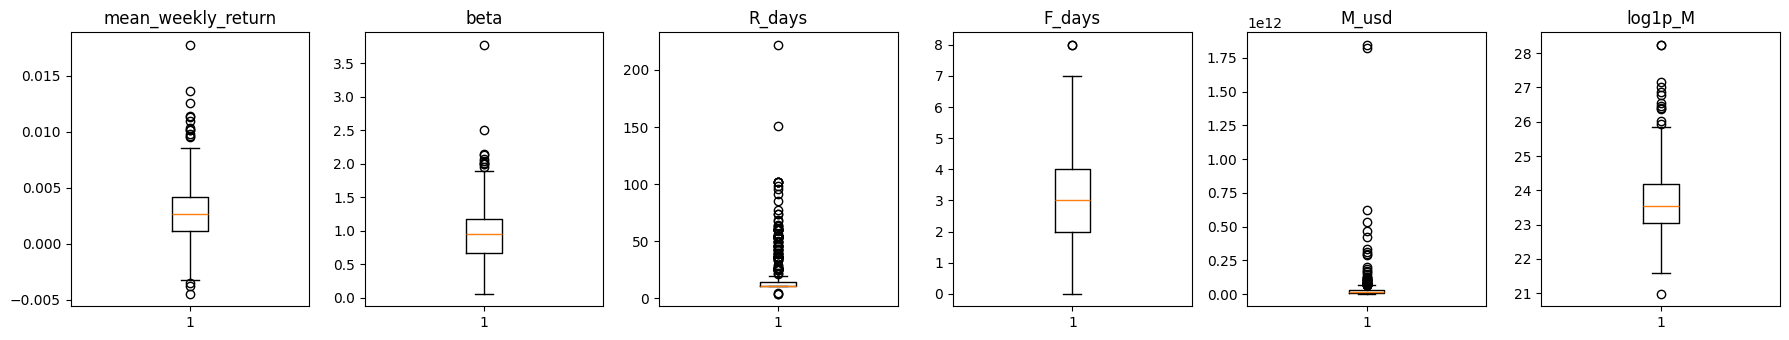

In [20]:
def outlier_report(data, cols):
    rows = {}
    for col in cols:
        s = data[col]
        q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
        z = (s - s.mean()) / s.std()
        rows[col] = {"skew": s.skew(), "iqr_outliers": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                     "extreme_|z|>4": int((z.abs() > 4).sum()), "min": s.min(), "median": s.median(), "max": s.max()}
    return pd.DataFrame(rows).T

display(outlier_report(df, RR_COLS + ["R_days", "F_days", "M_usd", "log1p_M"]))

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, col in zip(axes, RR_COLS + ["R_days", "F_days", "M_usd", "log1p_M"]):
    ax.boxplot(df[col].dropna()); ax.set_title(col)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/feature_boxplots.png", dpi=150); plt.show()

In [21]:
# Largest values: check they are real shares, not data errors
for col in ["mean_weekly_return", "beta", "R_days", "M_usd"]:
    print(col, "| top 3:", df[col].nlargest(3).round(4).to_dict())

mean_weekly_return | top 3: {'SMCI': 0.0178, 'NVDA': 0.0136, 'VRT': 0.0126}
beta | top 3: {'CVNA': 3.7786, 'XYZ': 2.5045, 'COHR': 2.1393}
R_days | top 3: {'NVDA': 222, 'WEC': 151, 'COR': 102}
M_usd | top 3: {'TSLA': 1847697379221.8428, 'NVDA': 1825336654239.194, 'AAPL': 623303377706.5842}


In [22]:
X_rr = pd.DataFrame(StandardScaler().fit_transform(df[RR_COLS]), index=df.index, columns=RR_COLS)
X_rfm = pd.DataFrame(StandardScaler().fit_transform(df[RFM_COLS]), index=df.index, columns=RFM_COLS)
MATRICES = {"RR": X_rr, "RFM": X_rfm}
print(X_rr.describe().loc[["mean", "std"]].round(3)); print(X_rfm.describe().loc[["mean", "std"]].round(3))

      mean_weekly_return   beta
mean               0.000  0.000
std                1.001  1.001
      R_days  F_days  log1p_M
mean  -0.000  -0.000   -0.000
std    1.001   1.001    1.001


## 2.2 Agglomerative clustering (Ward linkage, Euclidean distance)

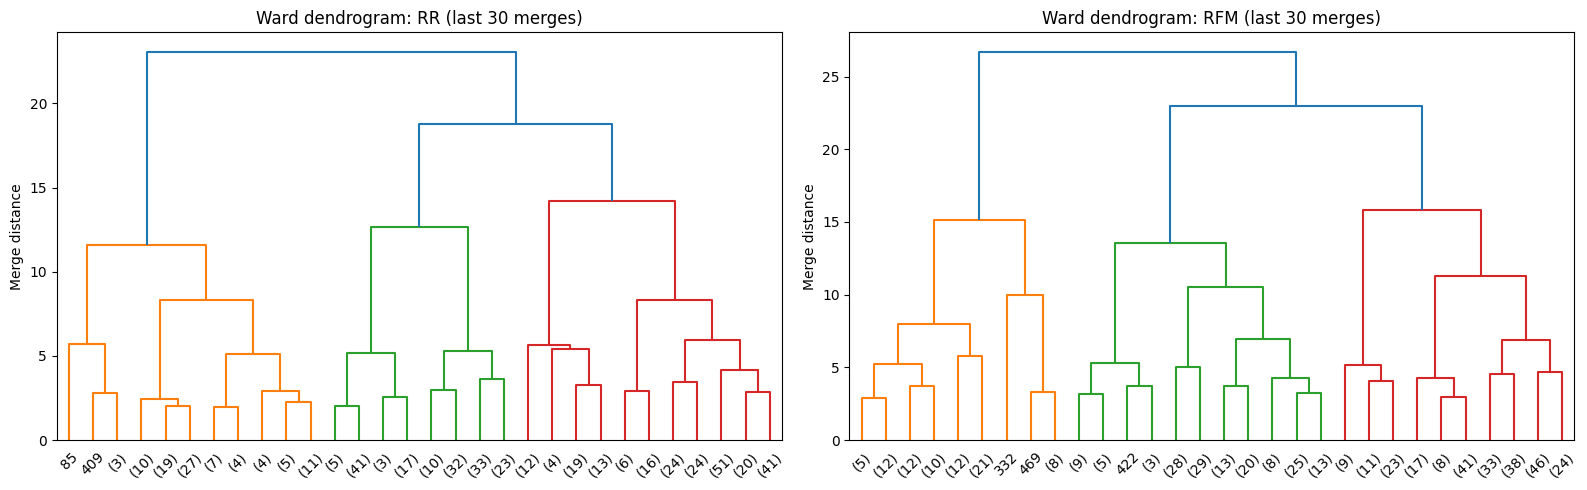

In [23]:
ward_trees = {name: linkage(X.values, method="ward", metric="euclidean") for name, X in MATRICES.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, Z) in zip(axes, ward_trees.items()):
    dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, ax=ax)
    ax.set_title(f"Ward dendrogram: {name} (last 30 merges)"); ax.set_ylabel("Merge distance")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/ward_dendrograms.png", dpi=150); plt.show()

In [24]:
def ward_table(name):
    X, Z = MATRICES[name], ward_trees[name]
    rows = []
    for k in K_RANGE:
        lab = fcluster(Z, k, criterion="maxclust")
        sizes = sorted(np.bincount(lab)[1:], reverse=True)
        rows.append({"k": k, "silhouette": silhouette_score(X, lab), "min_size": min(sizes), "sizes": sizes})
    return pd.DataFrame(rows)

def suggest_k(table, min_size):
    ok = table[table["min_size"] >= min_size]
    pick = ok if len(ok) else table
    return int(pick.loc[pick["silhouette"].idxmax(), "k"])

MIN_SIZE = max(10, int(0.03 * len(df)))     # avoid tiny clusters that cannot be profiled
ward_tables = {name: ward_table(name) for name in MATRICES}
for name, t in ward_tables.items():
    print(f"\nWard {name} (suggested k = {suggest_k(t, MIN_SIZE)}, min cluster size rule = {MIN_SIZE})")
    display(t.round(3))


Ward RR (suggested k = 2, min cluster size rule = 14)


,k,silhouette,min_size,sizes
0,2,0.339,92,"[394, 92]"
1,3,0.274,92,"[230, 164, 92]"
2,4,0.282,48,"[182, 164, 92, 48]"
3,5,0.304,48,"[182, 98, 92, 66, 48]"
4,6,0.320,5,"[182, 98, 87, 66, 48, 5]"
5,7,0.324,5,"[160, 98, 87, 66, 48, 22, 5]"
6,8,0.321,5,"[160, 98, 66, 56, 48, 31, 22, 5]"



Ward RFM (suggested k = 2, min cluster size rule = 14)


,k,silhouette,min_size,sizes
0,2,0.368,82,"[404, 82]"
1,3,0.304,82,"[250, 154, 82]"
2,4,0.289,43,"[207, 154, 82, 43]"
3,5,0.305,10,"[207, 154, 72, 43, 10]"
4,6,0.314,10,"[207, 136, 72, 43, 18, 10]"
5,7,0.292,10,"[141, 136, 72, 66, 43, 18, 10]"
6,8,0.302,10,"[141, 79, 72, 66, 57, 43, 18, 10]"


k was chosen from silhouette, cluster sizes and whether the profiles can be interpreted. The automatic suggestion (k = 2) only splits shares into high and low groups, so k = 5 (risk and return) and k = 4 (RFM) were used.

In [25]:
# Chosen k after reviewing silhouette, cluster sizes and profiles (see the note above)
K_WARD = {"RR": 5, "RFM": 4}
labels = {f"ward_{n}": fcluster(ward_trees[n], K_WARD[n], criterion="maxclust") for n in MATRICES}
print(K_WARD)

{'RR': 5, 'RFM': 4}


## 2.3 K-means

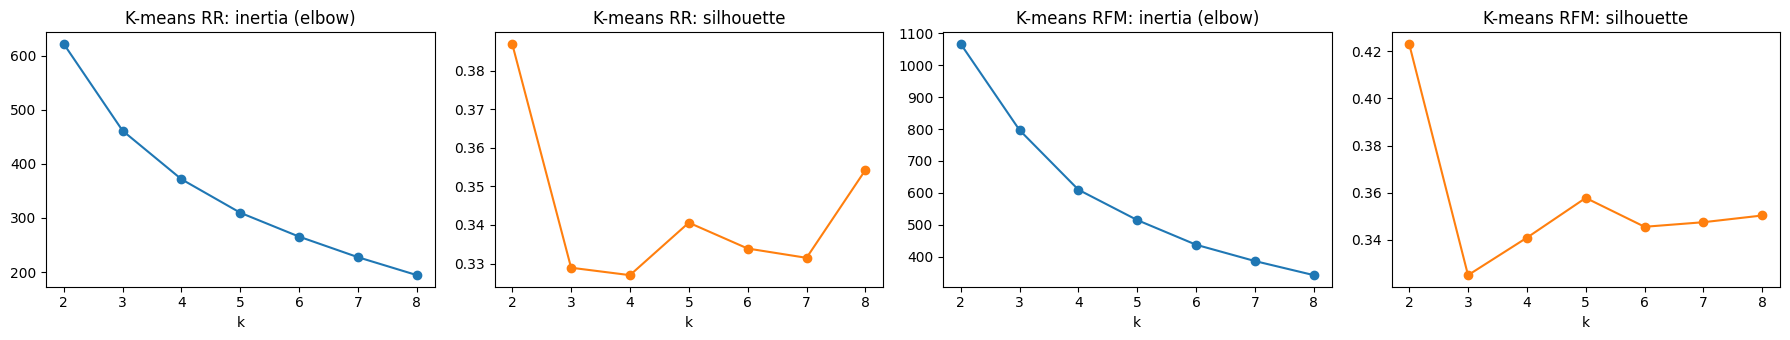


K-means RR (suggested k = 2)


,k,silhouette,inertia,min_size,sizes
0,2,0.387,621.634,143,"[343, 143]"
1,3,0.329,461.179,119,"[202, 165, 119]"
2,4,0.327,371.577,40,"[160, 154, 132, 40]"
3,5,0.341,309.613,27,"[166, 131, 112, 50, 27]"
4,6,0.334,265.448,5,"[158, 113, 111, 56, 43, 5]"
5,7,0.331,227.476,5,"[143, 85, 83, 74, 48, 48, 5]"
6,8,0.354,194.362,5,"[136, 79, 78, 76, 43, 40, 29, 5]"



K-means RFM (suggested k = 2)


,k,silhouette,inertia,min_size,sizes
0,2,0.423,1066.832,68,"[418, 68]"
1,3,0.325,796.614,64,"[270, 152, 64]"
2,4,0.341,609.832,61,"[212, 122, 91, 61]"
3,5,0.358,514.714,11,"[198, 122, 87, 68, 11]"
4,6,0.346,437.422,11,"[141, 120, 104, 69, 41, 11]"
5,7,0.347,386.286,1,"[141, 120, 104, 68, 41, 11, 1]"
6,8,0.350,342.175,1,"[140, 106, 83, 66, 64, 15, 11, 1]"


In [26]:
def kmeans_table(name):
    X = MATRICES[name]
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
        sizes = sorted(np.bincount(km.labels_), reverse=True)
        rows.append({"k": k, "silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_,
                     "min_size": min(sizes), "sizes": sizes})
    return pd.DataFrame(rows)

km_tables = {name: kmeans_table(name) for name in MATRICES}

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for i, (name, t) in enumerate(km_tables.items()):
    axes[2 * i].plot(t["k"], t["inertia"], marker="o"); axes[2 * i].set_title(f"K-means {name}: inertia (elbow)")
    axes[2 * i + 1].plot(t["k"], t["silhouette"], marker="o", color="tab:orange")
    axes[2 * i + 1].set_title(f"K-means {name}: silhouette")
    for ax in axes[2 * i:2 * i + 2]: ax.set_xlabel("k")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/kmeans_k_selection.png", dpi=150); plt.show()

for name, t in km_tables.items():
    print(f"\nK-means {name} (suggested k = {suggest_k(t, MIN_SIZE)})"); display(t.round(3))

In [27]:
# Same k as Ward so the two algorithms can be compared on equal terms
K_KM = {"RR": 5, "RFM": 4}
km_models = {n: KMeans(n_clusters=K_KM[n], n_init=20, random_state=SEED).fit(MATRICES[n]) for n in MATRICES}
for n in MATRICES:
    labels[f"kmeans_{n}"] = km_models[n].labels_ + 1          # number clusters from 1, like Ward
print(K_KM)

{'RR': 5, 'RFM': 4}


In [28]:
# Robustness: refit K-means without extreme shares (|z| > 4) and compare memberships on the remaining shares
for n, X in MATRICES.items():
    keep = (X.abs() <= 4).all(axis=1)
    refit = KMeans(n_clusters=K_KM[n], n_init=20, random_state=SEED).fit(X[keep])
    ari = adjusted_rand_score(labels[f"kmeans_{n}"][keep.values], refit.labels_)
    print(f"{n}: dropped {int((~keep).sum())} extreme shares, ARI with baseline on the rest = {ari:.3f}")

RR: dropped 3 extreme shares, ARI with baseline on the rest = 0.855
RFM: dropped 3 extreme shares, ARI with baseline on the rest = 0.948


## 2.4 Cluster profiles and algorithm comparison

In [29]:
assign = pd.DataFrame(labels, index=df.index)
prof_df = df.assign(mean_weekly_return_pct=df["mean_weekly_return"] * 100, M_usd_millions=df["M_usd"] / 1e6)

def profile(sol, cols):
    g = prof_df.groupby(assign[sol])
    out = g[cols].median().add_suffix(" (median)")
    out.insert(0, "n_shares", g.size())
    return out.round(3)

RR_SHOW = ["mean_weekly_return_pct", "beta"]
RFM_SHOW = ["R_days", "F_days", "M_usd_millions"]
for sol in ["ward_RR", "kmeans_RR"]:
    print(sol); display(profile(sol, RR_SHOW))
for sol in ["ward_RFM", "kmeans_RFM"]:
    print(sol); display(profile(sol, RFM_SHOW))

ward_RR


,n_shares,mean_weekly_return_pct (median),beta (median)
ward_RR,,,
1,92,0.550,1.218
2,66,0.113,0.448
3,98,0.392,0.666
4,48,0.252,1.514
5,182,0.166,0.964


kmeans_RR


,n_shares,mean_weekly_return_pct (median),beta (median)
kmeans_RR,,,
1,112,0.075,1.032
2,166,0.415,0.996
3,131,0.203,0.530
4,27,0.831,1.450
5,50,0.267,1.543


ward_RFM


,n_shares,R_days (median),F_days (median),M_usd_millions (median)
ward_RFM,,,,
1,82,54.5,2.0,17849.027
2,154,11.0,3.0,39695.450
3,43,11.0,5.0,14429.973
4,207,11.0,3.0,10785.266


kmeans_RFM


,n_shares,R_days (median),F_days (median),M_usd_millions (median)
kmeans_RFM,,,,
1,122,11.0,4.0,12825.893
2,61,55.0,2.0,21242.121
3,212,11.0,2.0,13336.412
4,91,11.0,3.0,60183.441


**Visuals.** Risk and return has only two features, so it is plotted directly in original units (no reduction needed).
RFM has three features, so PCA projects the standardised features onto two components; the explained variance and loadings are reported.

PCA explained variance: [0.458 0.336] | total: 0.794


,PC1,PC2
R_days,0.711,0.023
F_days,-0.650,0.402
log1p_M,0.268,0.915


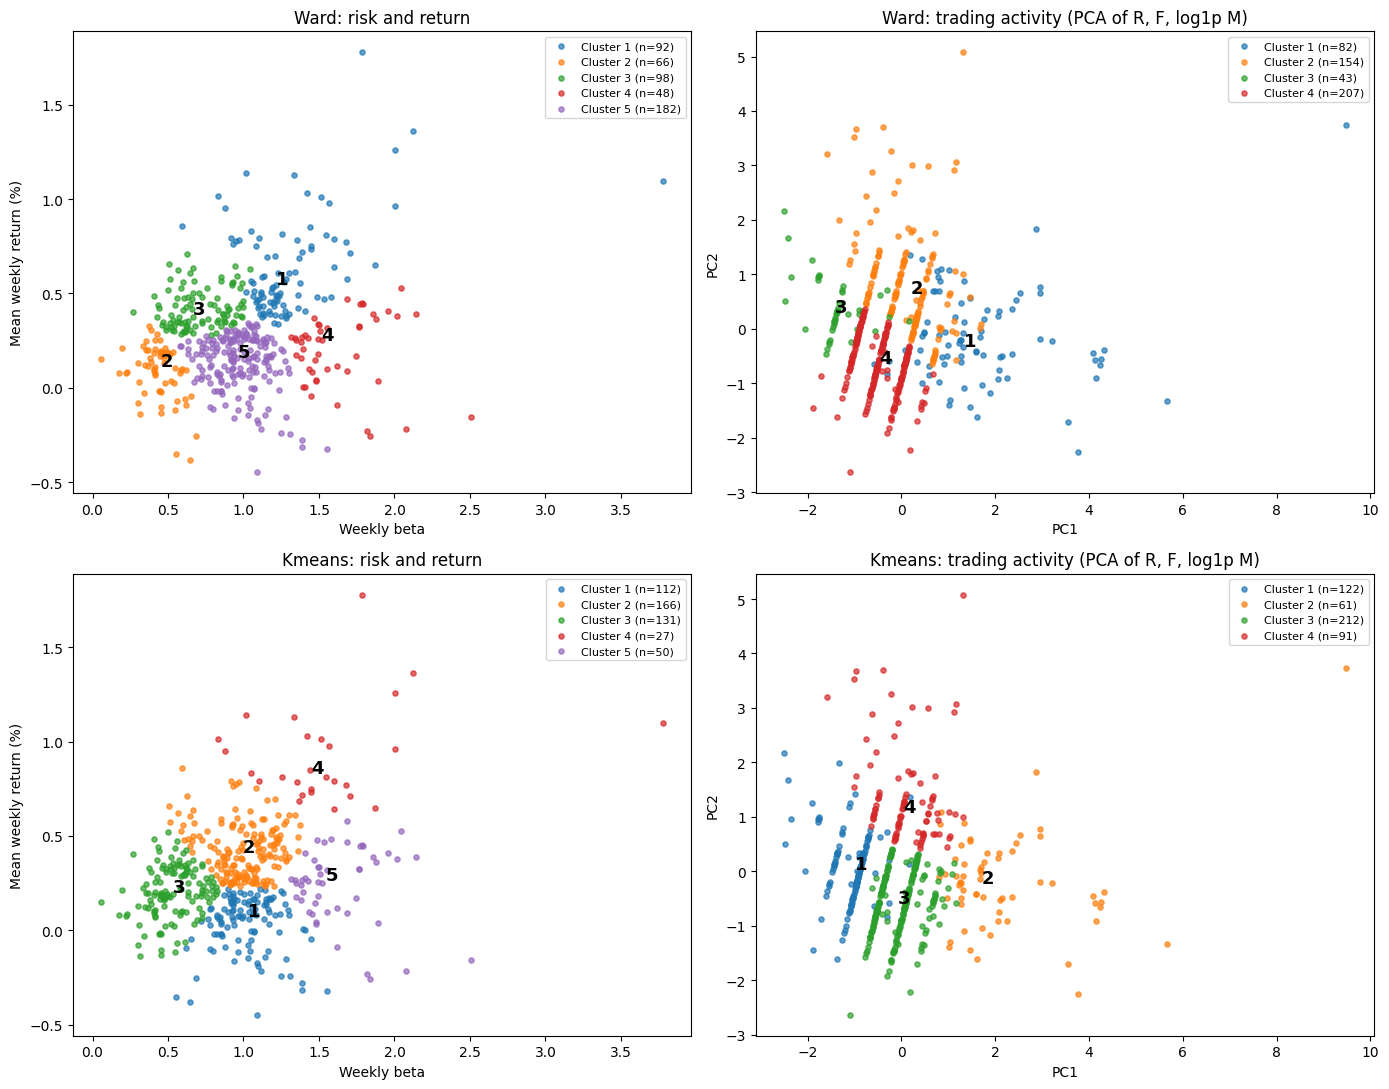

In [30]:
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
pcs = pd.DataFrame(pca.transform(X_rfm), index=df.index, columns=["PC1", "PC2"])
print("PCA explained variance:", pca.explained_variance_ratio_.round(3), "| total:", pca.explained_variance_ratio_.sum().round(3))
display(pd.DataFrame(pca.components_.T, index=RFM_COLS, columns=["PC1", "PC2"]).round(3))

def scatter(ax, x, y, lab, title, xlabel, ylabel):
    for c in sorted(np.unique(lab)):
        m = lab == c
        ax.scatter(x[m], y[m], s=14, alpha=0.7, label=f"Cluster {c} (n={m.sum()})")
        ax.annotate(str(c), (np.median(x[m]), np.median(y[m])), fontsize=13, weight="bold")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for i, alg in enumerate(["ward", "kmeans"]):
    scatter(axes[i, 0], prof_df["beta"].values, prof_df["mean_weekly_return_pct"].values, assign[f"{alg}_RR"].values,
            f"{alg.title()}: risk and return", "Weekly beta", "Mean weekly return (%)")
    scatter(axes[i, 1], pcs["PC1"].values, pcs["PC2"].values, assign[f"{alg}_RFM"].values,
            f"{alg.title()}: trading activity (PCA of R, F, log1p M)", "PC1", "PC2")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/cluster_scatter.png", dpi=150); plt.show()

In [31]:
# Same shares, two algorithms: agreement measured by adjusted Rand index (ignores cluster numbering)
for n in MATRICES:
    print(f"{n}: ARI Ward vs K-means = {adjusted_rand_score(assign[f'ward_{n}'], assign[f'kmeans_{n}']):.3f}")
    display(pd.crosstab(assign[f"ward_{n}"], assign[f"kmeans_{n}"], rownames=["Ward"], colnames=["K-means"]))

RR: ARI Ward vs K-means = 0.318


K-means,1,2,3,4,5
Ward,,,,,
1,0,60,0,27,5
2,5,0,61,0,0
3,0,57,41,0,0
4,3,0,0,0,45
5,104,49,29,0,0


RFM: ARI Ward vs K-means = 0.343


K-means,1,2,3,4
Ward,,,,
1,4,57,14,7
2,14,4,52,84
3,43,0,0,0
4,61,0,146,0


In [32]:
# For Task 3.2.1: risk and return clusters vs trading activity clusters, and sector composition
print(f"ARI Ward RR vs Ward RFM = {adjusted_rand_score(assign['ward_RR'], assign['ward_RFM']):.3f}")
display(pd.crosstab(assign["ward_RR"], assign["ward_RFM"], rownames=["Ward RR"], colnames=["Ward RFM"]))
for sol in ["ward_RR", "ward_RFM"]:
    print(f"Sector composition (% of each cluster), {sol}")
    display((pd.crosstab(assign[sol], df["GICS Sector"], normalize="index") * 100).round(1))

ARI Ward RR vs Ward RFM = 0.040


Ward RFM,1,2,3,4
Ward RR,,,,
1,19,37,12,24
2,16,23,4,23
3,10,35,6,47
4,9,20,6,13
5,28,39,15,100


Sector composition (% of each cluster), ward_RR


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
ward_RR,,,,,,,,,,,
1,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1
2,4.5,0.0,33.3,0.0,3.0,28.8,3.0,0.0,1.5,1.5,24.2
3,5.1,9.2,5.1,16.3,28.6,8.2,11.2,2.0,3.1,3.1,8.2
4,0.0,20.8,0.0,0.0,10.4,8.3,8.3,47.9,4.2,0.0,0.0
5,3.8,9.3,2.7,0.0,14.3,13.7,22.0,11.0,7.7,12.6,2.7


Sector composition (% of each cluster), ward_RFM


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
ward_RFM,,,,,,,,,,,
1,4.9,11.0,8.5,2.4,12.2,11.0,7.3,22.0,9.8,0.0,11.0
2,5.8,13.0,7.1,6.5,16.2,13.6,13.6,20.1,1.3,1.9,0.6
3,4.7,9.3,4.7,2.3,7.0,20.9,25.6,14.0,2.3,4.7,4.7
4,2.4,6.8,5.8,3.4,17.4,9.2,19.3,9.2,5.8,12.1,8.7


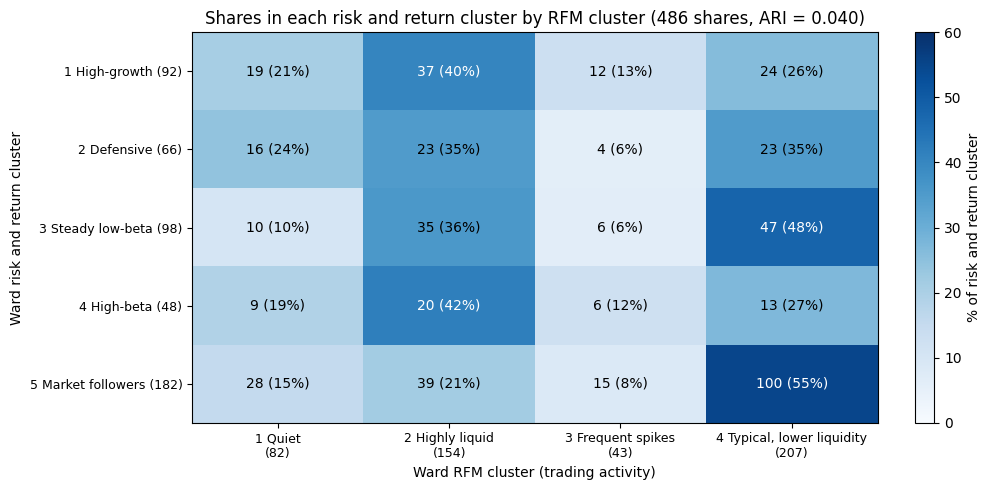

In [33]:
# Figure 6 (Task 3.2.1): Ward risk and return clusters vs Ward RFM clusters
import matplotlib.pyplot as plt

ct = pd.crosstab(assign["ward_RR"], assign["ward_RFM"])
pct = ct.div(ct.sum(axis=1), axis=0) * 100          # row % within each risk and return cluster
ari = adjusted_rand_score(assign["ward_RR"], assign["ward_RFM"])
rr_names = {1: "High-growth", 2: "Defensive", 3: "Steady low-beta", 4: "High-beta", 5: "Market followers"}
rfm_names = {1: "Quiet", 2: "Highly liquid", 3: "Frequent spikes", 4: "Typical, lower liquidity"}

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(pct.values, cmap="Blues", vmin=0, vmax=60, aspect="auto")
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct.iat[i, j]} ({pct.iat[i, j]:.0f}%)", ha="center", va="center",
                color="white" if pct.iat[i, j] > 40 else "black")
ax.set_xticks(range(ct.shape[1]))
ax.set_xticklabels([f"{c} {rfm_names[c]}\n({ct[c].sum()})" for c in ct.columns], fontsize=9)
ax.set_yticks(range(ct.shape[0]))
ax.set_yticklabels([f"{r} {rr_names[r]} ({ct.loc[r].sum()})" for r in ct.index], fontsize=9)
ax.set_xlabel("Ward RFM cluster (trading activity)")
ax.set_ylabel("Ward risk and return cluster")
fig.colorbar(im, ax=ax, fraction=0.03, label="% of risk and return cluster")
ax.set_title(f"Shares in each risk and return cluster by RFM cluster ({len(assign)} shares, ARI = {ari:.3f})")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/rr_vs_rfm_heatmap.png", dpi=150)
plt.show()

## 2.5 RFM sensitivity and correlated inputs

### 2.5.1 Correlations among R, F and log1p(M)

Pearson                Spearman               
         R_days F_days log1p_M   R_days F_days log1p_M
R_days    1.000 -0.346   0.152    1.000 -0.196   0.137
F_days   -0.346  1.000   0.013   -0.196  1.000  -0.048
log1p_M   0.152  0.013   1.000    0.137 -0.048   1.000

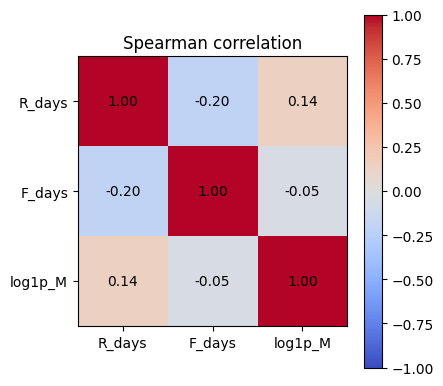

In [34]:
corr = pd.concat({"Pearson": df[RFM_COLS].corr(), "Spearman": df[RFM_COLS].corr(method="spearman")}, axis=1)
display(corr.round(3))

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(df[RFM_COLS].corr(method="spearman"), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(3), RFM_COLS); ax.set_yticks(range(3), RFM_COLS)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{df[RFM_COLS].corr(method='spearman').iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Spearman correlation"); plt.colorbar(im)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/rfm_correlation.png", dpi=150); plt.show()

### 2.5.2 Removal of Monetary

In [35]:
X_rf = pd.DataFrame(StandardScaler().fit_transform(df[["R_days", "F_days"]]), index=df.index, columns=["R_days", "F_days"])
assign["ward_RF_only"] = fcluster(linkage(X_rf.values, method="ward"), K_WARD["RFM"], criterion="maxclust")

ari = adjusted_rand_score(assign["ward_RFM"], assign["ward_RF_only"])
print(f"ARI Ward RFM vs Ward RF-only (k = {K_WARD['RFM']}): {ari:.3f}  (1 = identical groups, about 0 = unrelated)")
display(pd.crosstab(assign["ward_RFM"], assign["ward_RF_only"], rownames=["With M"], colnames=["Without M"]))

# Does M mainly separate liquidity levels? Compare traded value profiles of both solutions
for sol in ["ward_RFM", "ward_RF_only"]:
    print(f"Traded value profile, {sol}")
    display(profile(sol, ["M_usd_millions", "R_days", "F_days"]))

ARI Ward RFM vs Ward RF-only (k = 4): 0.203  (1 = identical groups, about 0 = unrelated)


Without M,1,2,3,4
With M,,,,
1,10,69,0,3
2,0,9,59,86
3,0,1,0,42
4,0,0,66,141


Traded value profile, ward_RFM


,n_shares,M_usd_millions (median),R_days (median),F_days (median)
ward_RFM,,,,
1,82,17849.027,54.5,2.0
2,154,39695.450,11.0,3.0
3,43,14429.973,11.0,5.0
4,207,10785.266,11.0,3.0


Traded value profile, ward_RF_only


,n_shares,M_usd_millions (median),R_days (median),F_days (median)
ward_RF_only,,,,
1,10,23785.946,102.0,0.0
2,79,20131.668,49.0,2.0
3,125,17698.993,11.0,2.0
4,272,14855.344,11.0,4.0


Reading it: if the ARI is low and the with-M clusters differ mainly in median traded value, M is mostly separating
liquidity levels rather than activity patterns. Traded value is only a liquidity proxy (no spread or price impact).

## Save assignments

In [36]:
out = df[["Security", "GICS Sector"] + RR_COLS + ["R_days", "F_days", "M_usd", "log1p_M"]].join(assign)
out.to_csv(f"{DATA_DIR}/cluster_assignments.csv")
with open(f"{DATA_DIR}/task2_settings.json", "w") as f:
    json.dump({"seed": SEED, "n_init": 20, "k_ward": K_WARD, "k_kmeans": K_KM, "min_cluster_size_rule": MIN_SIZE,
               "n_shares": len(df), "pca_explained_variance": pca.explained_variance_ratio_.round(4).tolist()}, f, indent=2)
out.head()

,Security,GICS Sector,mean_weekly_return,beta,R_days,F_days,M_usd,log1p_M,ward_RR,ward_RFM,kmeans_RR,kmeans_RFM,ward_RF_only
Ticker,,,,,,,,,,,,,
MMM,3M,Industrials,0.001142,0.869079,11,4,2.599146e+10,23.981034,5,2,1,1,4
AOS,A. O. Smith,Industrials,0.001991,1.042805,11,2,4.748980e+09,22.281196,5,4,1,3,3
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,11,1,3.523027e+10,24.285172,2,2,3,3,3
ABBV,AbbVie,Health Care,0.003749,0.425367,11,3,6.837054e+10,24.948208,3,2,3,4,4
ACN,Accenture,Information Technology,0.002376,1.143300,11,2,5.199430e+10,24.674400,5,2,2,4,3


In [37]:
!zip -r outputs.zip data figures
from google.colab import files; files.download("outputs.zip")

  adding: data/ (stored 0%)
  adding: data/constituents.csv (deflated 71%)
  adding: data/close.csv (deflated 77%)
  adding: data/metadata.json (deflated 38%)
  adding: data/inclusion_exclusion_log.csv (deflated 92%)
  adding: data/adj_close.csv (deflated 62%)
  adding: data/feature_table.csv (deflated 61%)
  adding: data/splits.csv (deflated 99%)
  adding: data/cluster_assignments.csv (deflated 54%)
  adding: data/volume.csv (deflated 62%)
  adding: data/task2_settings.json (deflated 37%)
  adding: data/benchmark_gspc.csv (deflated 79%)
  adding: data/dividends.csv (deflated 98%)
  adding: figures/ (stored 0%)
  adding: figures/cluster_scatter.png (deflated 10%)
  adding: figures/kmeans_k_selection.png (deflated 10%)
  adding: figures/feature_boxplots.png (deflated 21%)
  adding: figures/rfm_correlation.png (deflated 13%)
  adding: figures/rr_vs_rfm_heatmap.png (deflated 8%)
  adding: figures/ward_dendrograms.png (deflated 20%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>